# Week 10 — Machine learning II: neural networks

Companion notebook of the tenth lecture. Sections 1–3 follow chapters 00–02 of the free online book [*Zero to Mastery Learn PyTorch for Deep Learning*](https://www.learnpytorch.io/) by Daniel Bourke (code under the MIT license): **tensors**, the **PyTorch workflow** on a straight line, and **classification** of points in the plane. Along the way we add the pieces of the lecture: backpropagation by hand, the learning rate, softmax and the cross-entropy. Sections 4–6 then train networks on this course's own data, the diamond prices of Week 9 and handwritten digits, with mini-batches, a validation set and early stopping.

**How to run**: Colab (PyTorch is preinstalled) or Anaconda locally (`pip install torch`), from the [course repository](https://github.com/liwt31/MathModel). Run cells in order with `Shift+Enter`. Everything runs on a laptop CPU in a few minutes; a GPU is used automatically if one is present.

**Note.** The exercises here and on the slides are **practice for yourself**, and they are **not** the graded assignments. Problem sets are released separately on Blackboard, with due dates.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
try:                                  # optional style file, ships with the course
    plt.style.use("mm.mplstyle")
except OSError:
    pass
plt.rcParams.update({"figure.figsize": (6.4, 4.0), "figure.dpi": 100, "legend.fontsize": 9,
                     "legend.framealpha": 0.9, "axes.titlesize": 11})

DATA = "https://raw.githubusercontent.com/liwt31/MathModel/refs/heads/2026/data/"
def load(file):
    try:
        return pd.read_csv(DATA + file)
    except Exception:                   # offline fallback: the repo's data/ folder
        return pd.read_csv("data/" + file)
torch.__version__

'2.15.0+cpu'

## 1. Tensors

A **tensor** is PyTorch's array. Everything Week 1 showed for NumPy arrays carries over: `shape` and `ndim`, element-wise arithmetic, `@` for matrix products, `reshape`, indexing, and constructors such as `zeros`, `ones` and `arange`. Three things are new, and they are the reason PyTorch exists: tensors default to 32-bit numbers, they can live on a graphics card (GPU), and they can record the computations done with them, so that slopes come for free (section 2.4). An image, for example, is a tensor of shape `[3, 224, 224]`: 3 colour channels (red, green, blue), 224 rows and 224 columns of pixels.

![an image becomes a tensor](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/00-tensor-shape-example-of-image.png)

*An image is turned into a tensor of shape `[3, 224, 224]`: colour channels, height, width. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/00-tensor-shape-example-of-image.png) (Daniel Bourke).*

| NumPy (Week 1) | PyTorch |
|---|---|
| `np.array([[7, 8], [9, 10]])` | `torch.tensor([[7, 8], [9, 10]])` |
| `np.random.rand(3, 4)` | `torch.rand(3, 4)` |
| `np.zeros((3, 4))`, `np.ones((3, 4))`, `np.arange(0, 10)` | `torch.zeros(3, 4)`, `torch.ones(3, 4)`, `torch.arange(0, 10)` |
| `a.shape`, `a.ndim`, `a.dtype` | `t.shape`, `t.ndim`, `t.dtype`, and also `t.device` |
| `a @ b`, `a.T`, `a.reshape(1, 7)` | `t @ u`, `t.T`, `t.reshape(1, 7)` |
| `a.max()`, `a.argmax()`, `a.mean()` | `t.max()`, `t.argmax()`, `t.mean()` (needs a float tensor) |
| `a.astype(np.float16)` | `t.type(torch.float16)` |

### 1.1 Creating tensors

The number of dimensions is `ndim` (count the square brackets on one side), and the size along each is `shape`. A network starts from **random numbers** and adjusts them as it looks at data, so random tensors are the most common way tensors are created in practice.

![scalar, vector, matrix and tensor](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/00-scalar-vector-matrix-tensor.png)

*A scalar, a vector, a matrix and a tensor. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/00-scalar-vector-matrix-tensor.png) (Daniel Bourke).*

In [2]:
scalar = torch.tensor(7)
vector = torch.tensor([7, 7])
MATRIX = torch.tensor([[7, 8],
                       [9, 10]])
TENSOR = torch.tensor([[[1, 2, 3],
                        [3, 6, 9],
                        [2, 4, 5]]])
for name, t in [("scalar", scalar), ("vector", vector), ("MATRIX", MATRIX), ("TENSOR", TENSOR)]:
    print(f"{name:7s} ndim = {t.ndim}, shape = {tuple(t.shape)}")
print("the Python number inside the scalar:", scalar.item())
print("TENSOR along dim 0, 1, 2 has sizes", TENSOR.shape[0], TENSOR.shape[1], TENSOR.shape[2])
print("random (3, 4):\n", torch.rand(size=(3, 4)))
print("an image-sized random tensor:", torch.rand(size=(224, 224, 3)).shape)
print(torch.zeros(size=(2, 4)), torch.ones(size=(2, 4)), torch.arange(start=0, end=10, step=1), sep="\n")

scalar  ndim = 0, shape = ()
vector  ndim = 1, shape = (2,)
MATRIX  ndim = 2, shape = (2, 2)
TENSOR  ndim = 3, shape = (1, 3, 3)
the Python number inside the scalar: 7
TENSOR along dim 0, 1, 2 has sizes 1 3 3
random (3, 4):
 tensor([[0.8103, 0.6146, 0.3622, 0.6711],
        [0.2315, 0.1663, 0.4732, 0.6841],
        [0.2874, 0.7261, 0.1950, 0.3883]])
an image-sized random tensor: torch.Size([224, 224, 3])
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.]])
tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])
tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])


![the dimensions of a tensor of shape (1, 3, 3)](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/00-pytorch-different-tensor-dimensions.png)

*The dimensions of `TENSOR`, outer to inner: `dim=0` has size 1, `dim=1` and `dim=2` have size 3. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/00-pytorch-different-tensor-dimensions.png) (Daniel Bourke).*

### 1.2 Datatype and device

The default number type is `torch.float32`, half the precision of NumPy's `float64`; it is accurate enough for networks and twice as fast. When PyTorch complains, check three attributes first: **what shape, what datatype, and where** (`shape`, `dtype`, `device`). Operations between tensors need matching datatypes and the same device.

In [3]:
some_tensor = torch.rand(3, 4)
print(f"Shape of tensor: {some_tensor.shape}")
print(f"Datatype of tensor: {some_tensor.dtype}")
print(f"Device tensor is stored on: {some_tensor.device}")
print("float16 version:", torch.tensor([3.0, 6.0, 9.0], dtype=torch.float16).dtype)
array = np.arange(1.0, 8.0)
print("from NumPy keeps float64:", torch.from_numpy(array).dtype, "; convert with .type(torch.float32) before feeding a network")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu
float16 version: torch.float16
from NumPy keeps float64: torch.float64 ; convert with .type(torch.float32) before feeding a network


### 1.3 Matrix multiplication and the most common error

Two rules decide whether a matrix product works:

1. The **inner dimensions** must match: `(3, 2) @ (3, 2)` fails, `(2, 3) @ (3, 2)` and `(3, 2) @ (2, 3)` work.
2. The result has the **outer dimensions**: `(2, 3) @ (3, 2)` gives `(2, 2)`, and `(3, 2) @ (2, 3)` gives `(3, 3)`.

Shape mismatches are the most common error in deep learning. The next cell provokes one on purpose and prints PyTorch's message; the transpose `.T` repairs it.

![animation of a matrix multiplication](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/00-matrix-multiply-crop.gif)

*Each entry of a matrix product is a row of the left matrix times a column of the right one. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/00-matrix-multiply-crop.gif) (Daniel Bourke).*

In [4]:
tensor = torch.tensor([1, 2, 3])
print("element-wise:", tensor * tensor, "  matrix multiplication:", tensor @ tensor)
tensor_A = torch.tensor([[1, 2], [3, 4], [5, 6]], dtype=torch.float32)
tensor_B = torch.tensor([[7, 10], [8, 11], [9, 12]], dtype=torch.float32)
try:
    torch.matmul(tensor_A, tensor_B)
except RuntimeError as err:
    print("RuntimeError:", err)
output = torch.matmul(tensor_A, tensor_B.T)
print(f"{tuple(tensor_A.shape)} @ {tuple(tensor_B.T.shape)} <- inner dimensions match, output shape {tuple(output.shape)}\n", output)

element-wise: tensor([1, 4, 9])   matrix multiplication: tensor(14)
RuntimeError: mm: mat1 and mat2 shapes cannot be multiplied (3x2 and 3x2)
(3, 2) @ (2, 3) <- inner dimensions match, output shape (3, 3)
 tensor([[ 27.,  30.,  33.],
        [ 61.,  68.,  75.],
        [ 95., 106., 117.]])


### 1.4 A layer is a matrix multiplication

A fully connected layer `nn.Linear(in_features, out_features)` computes $y = x A^{\mathsf T} + b$, with a weight matrix $A$ of shape `(out_features, in_features)` and a bias vector $b$. Its weights start as random numbers; training will change them. Here the 3 rows of `tensor_A` are 3 examples with 2 features each, and the layer maps each to 6 numbers. (The lecture writes the same layer for one example as $\mathbf{h} = W\mathbf{x} + \mathbf{b}$.)

In [5]:
torch.manual_seed(42)
linear = nn.Linear(in_features=2, out_features=6)
output = linear(tensor_A)
print("weight shape", tuple(linear.weight.shape), " bias shape", tuple(linear.bias.shape))
print("input shape", tuple(tensor_A.shape), "-> output shape", tuple(output.shape))
print("same as the formula:", torch.allclose(output, tensor_A @ linear.weight.T + linear.bias))

weight shape (6, 2)  bias shape (6,)
input shape (3, 2) -> output shape (3, 6)
same as the formula: True


### 1.5 Aggregation, and changing shapes

`argmax` gives the **position** of the largest value; a classifier uses it to pick the class with the largest score (section 3). Besides `reshape`, networks often need dimensions of size 1 added or removed, and images need their dimensions reordered:

| method | what it does |
|---|---|
| `x.view(shape)` | like `reshape`, but shares memory: changing the view changes `x` |
| `torch.stack([...], dim)` | puts tensors of equal shape on top of each other along a new dimension |
| `x.squeeze()` / `x.unsqueeze(dim)` | removes all dimensions of size 1 / adds one at position `dim` |
| `x.permute(order)` | rearranges the dimensions, e.g. `[height, width, channels]` → `[channels, height, width]` |

In [6]:
x = torch.arange(0, 100, 10)
print(f"Minimum: {x.min()}  Maximum: {x.max()}  Mean: {x.type(torch.float32).mean()}  Sum: {x.sum()}  argmax: {x.argmax()}  argmin: {x.argmin()}")
x = torch.arange(1., 8.)
z = x.view(1, 7); z[:, 0] = 5
print("changing the view changes x:", x)
print("stacked:", torch.stack([x, x, x], dim=0).shape)
print("unsqueeze(dim=1):", x.unsqueeze(dim=1).shape, " squeeze back:", x.unsqueeze(dim=1).squeeze().shape)
print("permute [h, w, c] -> [c, h, w]:", torch.rand(224, 224, 3).permute(2, 0, 1).shape)

Minimum: 0  Maximum: 90  Mean: 45.0  Sum: 450  argmax: 9  argmin: 0
changing the view changes x: tensor([5., 2., 3., 4., 5., 6., 7.])
stacked: torch.Size([3, 7])
unsqueeze(dim=1): torch.Size([7, 1])  squeeze back: torch.Size([7])
permute [h, w, c] -> [c, h, w]: torch.Size([3, 224, 224])


### 1.6 Reproducibility and the GPU

Random numbers are reproducible after `torch.manual_seed`. Graphics cards (GPUs) do matrix arithmetic much faster than a CPU; **device-agnostic** code uses the GPU when there is one and the CPU otherwise. Tensors and models move with `.to(device)`; NumPy only works on the CPU, so a GPU tensor goes back with `.cpu()` before `.numpy()`. In Colab, a GPU can be switched on under Runtime → Change runtime type.

In [7]:
torch.manual_seed(42); random_tensor_C = torch.rand(3, 4)
torch.manual_seed(42); random_tensor_D = torch.rand(3, 4)
print("same random numbers after resetting the seed:", torch.equal(random_tensor_C, random_tensor_D))
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, " number of GPUs:", torch.cuda.device_count())
tensor_on_device = torch.tensor([1, 2, 3]).to(device)
print(tensor_on_device, "->", tensor_on_device.cpu().numpy())

same random numbers after resetting the seed: True
device: cpu  number of GPUs: 0
tensor([1, 2, 3]) -> [1 2 3]


## 2. The PyTorch workflow

The workflow has six steps: prepare the data, build a model, fit the model to the data (training), make predictions and evaluate them, save and load the model, and put it all together. We practise it on data whose answer we know, a straight line $y = 0.7x + 0.3$.

![the PyTorch workflow](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01_a_pytorch_workflow.png)

*The PyTorch workflow. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01_a_pytorch_workflow.png) (Daniel Bourke).*

![machine learning in two parts](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-machine-learning-a-game-of-two-parts.png)

*Machine learning in two parts: turn the data into numbers, then build a model that learns patterns in those numbers. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-machine-learning-a-game-of-two-parts.png) (Daniel Bourke).*

### 2.1 Data, and a split into training and test sets

Fifty points with $x$ from 0 to 0.98. The split is **in order**: the first 40 points train, the last 10 test, so the test asks the model to continue the line beyond the training data.

tensor([[0.0000, 0.0200, 0.0400, 0.0600, 0.0800]]) tensor([[0.3000, 0.3140, 0.3280, 0.3420, 0.3560]])
40 40 10 10


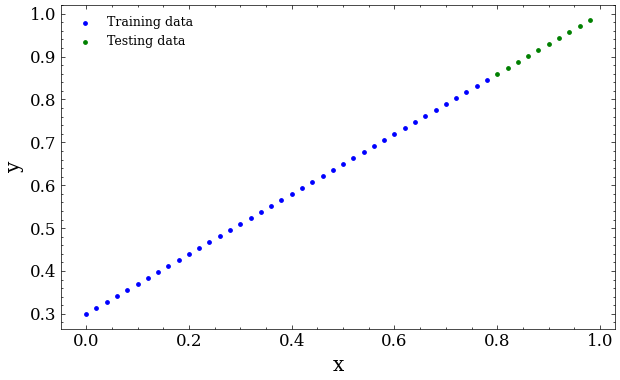

In [8]:
weight, bias = 0.7, 0.3
start, end, step = 0, 1, 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)        # shape (50, 1): 50 examples with 1 feature
y = weight * X + bias
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]
print(X[:5].T, y[:5].T)
print(len(X_train), len(y_train), len(X_test), len(y_test))

def plot_predictions(train_data=X_train, train_labels=y_train, test_data=X_test, test_labels=y_test, predictions=None):
    plt.figure(figsize=(6.4, 4.0))
    plt.scatter(train_data, train_labels, c="b", s=6, label="Training data")
    plt.scatter(test_data, test_labels, c="g", s=6, label="Testing data")
    if predictions is not None:
        plt.scatter(test_data, predictions, c="r", s=6, label="Predictions")
    plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.tight_layout(); plt.show()
plot_predictions()

### 2.2 Building a model

A PyTorch model is a class that inherits from `nn.Module`. Its numbers to be learned are `nn.Parameter`s, and its `forward` method says what it computes. Here the model has one weight and one bias and computes `weights * x + bias`, a straight line with random start values.

| building block | what it does |
|---|---|
| `torch.nn` | everything for building networks: layers, activations, losses |
| `nn.Parameter` | a tensor the model will learn; gradients are tracked for it |
| `nn.Module` | the base class of every model; subclasses must define `forward()` |
| `torch.optim` | optimizers, the rules that change the parameters (gradient descent, Adam) |

![an annotated PyTorch linear regression model](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-linear-model-annotated.png)

*The parts of `LinearRegressionModel`. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-linear-model-annotated.png) (Daniel Bourke).*

In [9]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)
        self.bias = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.weights * x + self.bias

torch.manual_seed(42)
model_0 = LinearRegressionModel()
print(list(model_0.parameters()))
print(model_0.state_dict())

[Parameter containing:
tensor([0.3367], requires_grad=True), Parameter containing:
tensor([0.1288], requires_grad=True)]
OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])


### 2.3 Predictions before training

`torch.inference_mode()` switches off the gradient bookkeeping when we only want predictions. With random parameters, the predictions (red) are far from the test points (green).

Number of testing samples: 10  Number of predictions made: 10
errors y_test - y_preds: tensor([0.4618, 0.4691, 0.4764, 0.4836, 0.4909, 0.4982, 0.5054, 0.5127, 0.5200,
        0.5272])


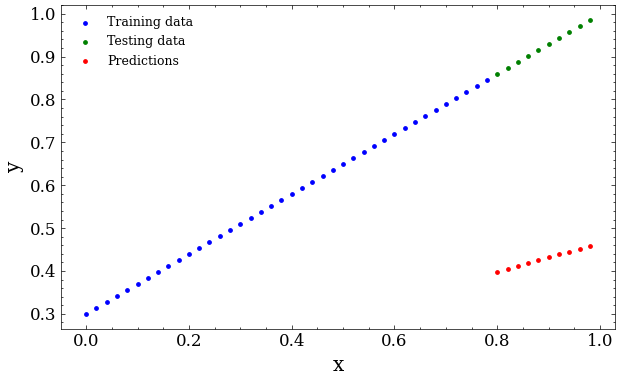

In [10]:
with torch.inference_mode():
    y_preds = model_0(X_test)
print("Number of testing samples:", len(X_test), " Number of predictions made:", len(y_preds))
print("errors y_test - y_preds:", (y_test - y_preds).squeeze())
plot_predictions(predictions=y_preds)

### 2.4 What `loss.backward()` computes

Training needs the slope of the loss with respect to every parameter. PyTorch records each computation on tensors with `requires_grad=True` as a **computational graph**, and `backward()` runs the chain rule from the output back to the inputs (**backpropagation**). The lecture's example is $F = x^2(x + y)$ at $x = 2$, $y = 3$: the forward pass gives $c = x^2 = 4$, $s = x + y = 5$, $F = cs = 20$, and the backward pass $\partial F/\partial x = 2x\cdot s + c = 24$, $\partial F/\partial y = c = 4$.

In [11]:
x = torch.tensor(2.0, requires_grad=True); y_ = torch.tensor(3.0, requires_grad=True)
c = x**2; s = x + y_; F = c * s
F.backward()
print("F =", F.item(), " dF/dx =", x.grad.item(), " dF/dy =", y_.grad.item())

F = 20.0  dF/dx = 24.0  dF/dy = 4.0


The lecture's tiny network: one input $x = 2$, two ReLU hidden units, a linear output, target $y = 4$ and loss $L = \frac12(\hat y - y)^2$, with weights $w_1 = 0.5,\ b_1 = 0,\ w_2 = -1,\ b_2 = 1,\ v_1 = 2,\ v_2 = 1,\ c = 0.5$. Autograd reproduces the forward pass, the seven slopes, and one gradient step by hand for two learning rates.

In [12]:
P0 = dict(w1=0.5, b1=0.0, w2=-1.0, b2=1.0, v1=2.0, v2=1.0, c=0.5)
def tiny(P, x=2.0, y=4.0):
    T = {k: torch.tensor(v, requires_grad=True) for k, v in P.items()}
    z1 = T["w1"] * x + T["b1"]; z2 = T["w2"] * x + T["b2"]
    h1, h2 = torch.relu(z1), torch.relu(z2)
    yhat = T["v1"] * h1 + T["v2"] * h2 + T["c"]
    L = 0.5 * (yhat - y) ** 2
    L.backward()
    return dict(z1=z1.item(), z2=z2.item(), h1=h1.item(), h2=h2.item(), yhat=yhat.item(), L=L.item()), {k: t.grad.item() for k, t in T.items()}
fwd, grad = tiny(P0)
print("forward :", fwd)
print("gradient:", grad)
for lr in [0.05, 0.1]:
    P1 = {k: P0[k] - lr * grad[k] for k in P0}
    print(f"after one step with learning rate {lr}: yhat = {tiny(P1)[0]['yhat']:.3f}, loss = {tiny(P1)[0]['L']:.4f}")

forward : {'z1': 1.0, 'z2': -1.0, 'h1': 1.0, 'h2': 0.0, 'yhat': 2.5, 'L': 1.125}
gradient: {'w1': -6.0, 'b1': -3.0, 'w2': 0.0, 'b2': 0.0, 'v1': -1.5, 'v2': -0.0, 'c': -1.5}
after one step with learning rate 0.05: yhat = 4.206, loss = 0.0213
after one step with learning rate 0.1: yhat = 6.025, loss = 2.0503


### 2.5 A loss function and an optimizer

The **loss** measures how wrong the predictions are; here the mean absolute error `nn.L1Loss()`, $\frac1n\sum|\hat y_i - y_i|$. The **optimizer** changes the parameters to lower the loss; here stochastic gradient descent `torch.optim.SGD` with learning rate `lr=0.01`, which moves every parameter by $-0.01$ times its slope.

![what the mean absolute error measures](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-mae-loss-annotated.png)

*The mean absolute error of the untrained model: the average length of the black lines between predictions (red) and test points (green). Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-mae-loss-annotated.png) (Daniel Bourke).*

In [13]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

### 2.6 The training loop and the testing loop

Each **epoch** is one pass through the training data. The training loop has five steps, always in this order:

| step | code | what it does |
|---|---|---|
| 1. forward pass | `y_pred = model(X_train)` | compute the predictions |
| 2. loss | `loss = loss_fn(y_pred, y_train)` | compare them with the labels |
| 3. zero the gradients | `optimizer.zero_grad()` | clear the slopes of the previous step (PyTorch adds them up otherwise) |
| 4. backward pass | `loss.backward()` | backpropagation: the slope of the loss for every parameter |
| 5. step | `optimizer.step()` | move every parameter against its slope |

The testing loop switches the model to evaluation mode, `model.eval()`, computes predictions inside `torch.inference_mode()`, and records the test loss. Nothing is learned from the test data.

![the PyTorch training loop, annotated](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-training-loop-annotated.png)

*The training loop, annotated. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-training-loop-annotated.png) (Daniel Bourke).*

![the PyTorch testing loop, annotated](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-testing-loop-annotated.png)

*The testing loop, annotated. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-testing-loop-annotated.png) (Daniel Bourke).*

In [14]:
torch.manual_seed(42)
epochs = 100
train_loss_values, test_loss_values, epoch_count = [], [], []
for epoch in range(epochs):
    model_0.train()
    y_pred = model_0(X_train)                   # 1. forward pass
    loss = loss_fn(y_pred, y_train)             # 2. loss
    optimizer.zero_grad()                       # 3. zero the gradients
    loss.backward()                             # 4. backward pass
    optimizer.step()                            # 5. step
    model_0.eval()
    with torch.inference_mode():
        test_pred = model_0(X_test)
        test_loss = loss_fn(test_pred, y_test)
    if epoch % 10 == 0:
        epoch_count.append(epoch); train_loss_values.append(loss.item()); test_loss_values.append(test_loss.item())
        print(f"Epoch: {epoch} | MAE Train Loss: {loss:.4f} | MAE Test Loss: {test_loss:.4f}")

Epoch: 0 | MAE Train Loss: 0.3129 | MAE Test Loss: 0.4811
Epoch: 10 | MAE Train Loss: 0.1977 | MAE Test Loss: 0.3464
Epoch: 20 | MAE Train Loss: 0.0891 | MAE Test Loss: 0.2173
Epoch: 30 | MAE Train Loss: 0.0531 | MAE Test Loss: 0.1446
Epoch: 40 | MAE Train Loss: 0.0454 | MAE Test Loss: 0.1136
Epoch: 50 | MAE Train Loss: 0.0417 | MAE Test Loss: 0.0992
Epoch: 60 | MAE Train Loss: 0.0382 | MAE Test Loss: 0.0889
Epoch: 70 | MAE Train Loss: 0.0348 | MAE Test Loss: 0.0806
Epoch: 80 | MAE Train Loss: 0.0313 | MAE Test Loss: 0.0723
Epoch: 90 | MAE Train Loss: 0.0279 | MAE Test Loss: 0.0647


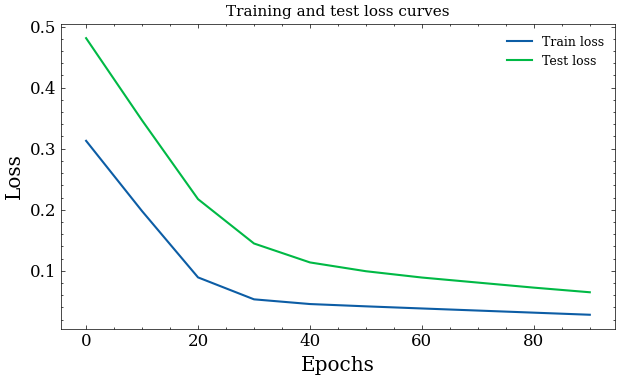

The model learned: OrderedDict([('weights', tensor([0.5784])), ('bias', tensor([0.3513]))])
The original values: weights 0.7, bias 0.3


In [15]:
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves"); plt.ylabel("Loss"); plt.xlabel("Epochs"); plt.legend(); plt.tight_layout(); plt.show()
print("The model learned:", model_0.state_dict())
print(f"The original values: weights {weight}, bias {bias}")

### 2.7 Predictions, saving and loading

After training, predictions again run in evaluation mode. A trained model is saved as its **state dictionary**, the named tensors of its parameters, with `torch.save`; loading creates a fresh model and fills in the saved values with `load_state_dict`.

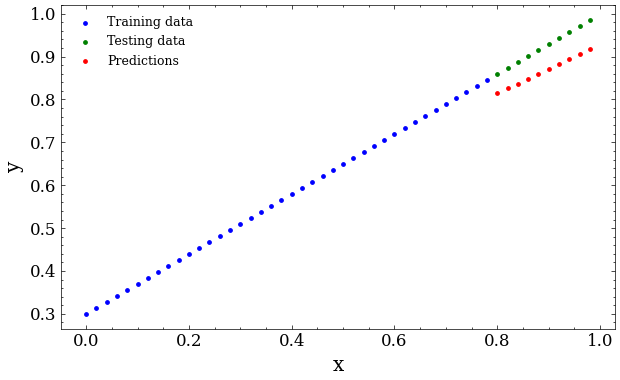

<All keys matched successfully>
loaded model gives the same predictions: True


In [16]:
from pathlib import Path
model_0.eval()
with torch.inference_mode():
    y_preds = model_0(X_test)
plot_predictions(predictions=y_preds)

MODEL_PATH = Path("models"); MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_PATH = MODEL_PATH / "01_pytorch_workflow_model_0.pth"
torch.save(obj=model_0.state_dict(), f=MODEL_SAVE_PATH)
loaded_model_0 = LinearRegressionModel()
print(loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH)))
loaded_model_0.eval()
with torch.inference_mode():
    loaded_model_preds = loaded_model_0(X_test)
print("loaded model gives the same predictions:", torch.equal(y_preds, loaded_model_preds))

### 2.8 Putting it all together

The same line with `nn.Linear(in_features=1, out_features=1)` in place of hand-made parameters, device-agnostic, trained for 1,000 epochs.

![nn.Parameter model and nn.Linear model compared](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-linear-regression-model-with-nn-Parameter-and-nn-Linear-compared.png)

*The same model written with `nn.Parameter` (left) and with `nn.Linear` (right). Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-linear-regression-model-with-nn-Parameter-and-nn-Linear-compared.png) (Daniel Bourke).*

OrderedDict([('linear_layer.weight', tensor([[0.7645]])), ('linear_layer.bias', tensor([0.8300]))])
Epoch: 0 | Train loss: 0.555178 | Test loss: 0.573976
Epoch: 100 | Train loss: 0.006216 | Test loss: 0.014087


Epoch: 200 | Train loss: 0.001265 | Test loss: 0.013802
Epoch: 300 | Train loss: 0.001265 | Test loss: 0.013802
Epoch: 400 | Train loss: 0.001265 | Test loss: 0.013802
Epoch: 500 | Train loss: 0.001265 | Test loss: 0.013802
Epoch: 600 | Train loss: 0.001265 | Test loss: 0.013802
Epoch: 700 | Train loss: 0.001265 | Test loss: 0.013802
Epoch: 800 | Train loss: 0.001265 | Test loss: 0.013802


Epoch: 900 | Train loss: 0.001265 | Test loss: 0.013802
learned: {'linear_layer.weight': 0.6968, 'linear_layer.bias': 0.3025}  true: weight 0.7, bias 0.3


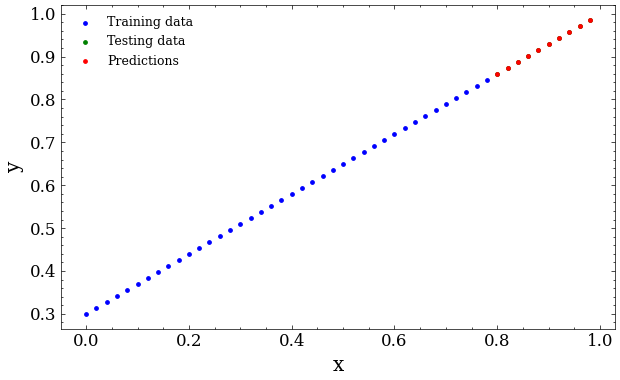

In [17]:
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer = nn.Linear(in_features=1, out_features=1)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)

torch.manual_seed(42)
model_1 = LinearRegressionModelV2().to(device)
print(model_1.state_dict())
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.01)
X_train, y_train, X_test, y_test = X_train.to(device), y_train.to(device), X_test.to(device), y_test.to(device)
torch.manual_seed(42)
epochs = 1000
for epoch in range(epochs):
    model_1.train()
    y_pred = model_1(X_train)
    loss = loss_fn(y_pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model_1.eval()
    with torch.inference_mode():
        test_loss = loss_fn(model_1(X_test), y_test)
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Train loss: {loss:.6f} | Test loss: {test_loss:.6f}")
print("learned:", {k: round(v.item(), 4) for k, v in model_1.state_dict().items()}, " true: weight 0.7, bias 0.3")
model_1.eval()
with torch.inference_mode():
    y_preds = model_1(X_test)
plot_predictions(X_train.cpu(), y_train.cpu(), X_test.cpu(), y_test.cpu(), predictions=y_preds.cpu())

### 2.9 The learning rate

The learning rate sets the step length. Fit a line $\hat y = wx + b$ to the 53,940 diamond prices of Week 9 by plain gradient descent on the squared error, with carat measured in standard deviations from its mean and the price in thousands of dollars. Too small a rate crawls, too large a rate explodes; and with an unscaled feature (carat × 100) no single rate works well. These are the numbers of the lecture.

In [18]:
d = load("diamonds.csv")
xc = torch.tensor(((d.carat - d.carat.mean()) / d.carat.std()).values, dtype=torch.float32)
yp = torch.tensor(d.price.values / 1000, dtype=torch.float32)
def gd_line(lr, steps=50, x=xc):
    w = torch.zeros(1, requires_grad=True); b = torch.zeros(1, requires_grad=True)
    for _ in range(steps):
        L = ((w * x + b - yp) ** 2).mean()
        L.backward()
        with torch.no_grad():
            w -= lr * w.grad; b -= lr * b.grad; w.grad.zero_(); b.grad.zero_()
    return ((w * x + b - yp) ** 2).mean().item(), w.item(), b.item()
A = torch.stack([xc, torch.ones_like(xc)], 1)
best = ((A @ torch.linalg.lstsq(A, yp[:, None]).solution).squeeze() - yp).pow(2).mean().item()
print(f"least-squares MSE (the bottom of the valley): {best:.3f}  (RMSE {1000 * best ** 0.5:.0f} $)")
for lr in [0.01, 0.1, 0.5, 0.9, 1.1]:
    L, w, b = gd_line(lr)
    print(f"learning rate {lr:4}: MSE after 50 steps {L:12.3f}   w = {w:8.3f}, b = {b:8.3f}")
xraw = torch.tensor(d.carat.values * 100, dtype=torch.float32)
for lr in [1e-4, 1.5e-4, 2e-4]:
    print(f"unscaled feature (carat x 100), learning rate {lr:g}: MSE after 50 steps {gd_line(lr, x=xraw)[0]:.4g}")

least-squares MSE (the bottom of the valley): 2.398  (RMSE 1549 $)
learning rate 0.01: MSE after 50 steps        6.242   w =    2.338, b =    2.501
learning rate  0.1: MSE after 50 steps        2.398   w =    3.677, b =    3.933
learning rate  0.5: MSE after 50 steps        2.398   w =    3.677, b =    3.933
learning rate  0.9: MSE after 50 steps        2.398   w =    3.677, b =    3.933
learning rate  1.1: MSE after 50 steps 2396640512.000   w = -33398.617, b = -35786.398
unscaled feature (carat x 100), learning rate 0.0001: MSE after 50 steps 3.72
unscaled feature (carat x 100), learning rate 0.00015: MSE after 50 steps 2.68e+21
unscaled feature (carat x 100), learning rate 0.0002: MSE after 50 steps inf


## 3. Classification

A classification network predicts a category.

![binary, multiclass and multilabel classification](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-different-classification-problems.png)

*Binary classification (one thing or another), multiclass classification (more than two classes), and multilabel classification (several labels per example). Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-different-classification-problems.png) (Daniel Bourke).*

The typical architecture:

| | binary classification | multiclass classification |
|---|---|---|
| input layer | one unit per feature | one unit per feature |
| hidden layers | at least 1, usually 1–5 | same |
| units per hidden layer | usually 10–512 | same |
| output layer | 1 unit | one unit per class |
| hidden activation | usually ReLU | same |
| output activation | sigmoid | softmax |
| loss | binary cross-entropy (`nn.BCEWithLogitsLoss`) | cross-entropy (`nn.CrossEntropyLoss`) |
| optimizer | SGD or Adam | same |

### 3.1 Data: two circles

1,000 points in the plane: a small circle (label 1) inside a large one (label 0), with a little noise.

         X1        X2  label
0  0.754246  0.231481      1
1 -0.756159  0.153259      1
2 -0.815392  0.173282      1
3 -0.393731  0.692883      1
4  0.442208 -0.896723      0
{1: 500, 0: 500}


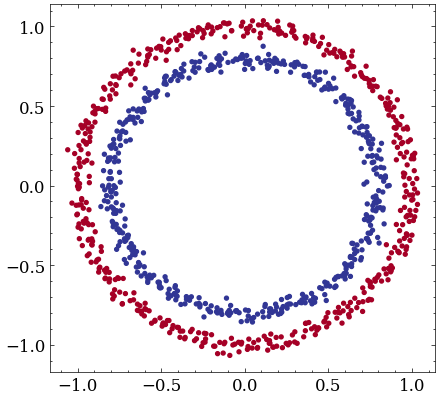

input shape (1000, 2)  output shape (1000,)  first example [0.75424625 0.23148074] 1


In [19]:
from sklearn.datasets import make_circles
n_samples = 1000
X, y = make_circles(n_samples, noise=0.03, random_state=42)
circles = pd.DataFrame({"X1": X[:, 0], "X2": X[:, 1], "label": y})
print(circles.head(5)); print(circles.label.value_counts().to_dict())
plt.figure(figsize=(4.6, 4.2))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, s=8); plt.tight_layout(); plt.show()
print("input shape", X.shape, " output shape", y.shape, " first example", X[0], y[0])

### 3.2 Tensors, and a random split

The NumPy arrays become `float32` tensors, and `train_test_split` puts a random 20% aside as the test set (the points are independent, so a random split is right here).

In [20]:
from sklearn.model_selection import train_test_split
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), len(X_test), len(y_train), len(y_test))

800 200 800 200


### 3.3 A first model

Two `nn.Linear` layers, 2 inputs → 5 units → 1 output, written as a class and, equivalently, with `nn.Sequential`, which chains layers in order. The output is one number per point, a **logit**: the raw score before any activation.

In [21]:
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=5)
        self.layer_2 = nn.Linear(in_features=5, out_features=1)
    def forward(self, x):
        return self.layer_2(self.layer_1(x))

model_0 = nn.Sequential(nn.Linear(in_features=2, out_features=5), nn.Linear(in_features=5, out_features=1)).to(device)
print(model_0)
X_train, y_train, X_test, y_test = X_train.to(device), y_train.to(device), X_test.to(device), y_test.to(device)
with torch.inference_mode():
    untrained_preds = model_0(X_test)
print("predictions shape", tuple(untrained_preds.shape), " first logits", untrained_preds[:3].squeeze())

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)
predictions shape (200, 1)  first logits tensor([-0.1269, -0.0967, -0.1908])


### 3.4 Loss, optimizer, and accuracy

`nn.BCEWithLogitsLoss` takes the raw logits, applies the logistic function (sigmoid) $\sigma(z) = 1/(1 + e^{-z})$ itself and charges the binary cross-entropy $-[y\ln p + (1 - y)\ln(1 - p)]$; doing both in one function is numerically safer. Accuracy is reported alongside.

In [22]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

### 3.5 From logits to probabilities to labels

logits → `torch.sigmoid` → probabilities between 0 and 1 → `torch.round` → labels 0 or 1 (label 1 when the probability is at least 0.5).

In [23]:
model_0.eval()
with torch.inference_mode():
    y_logits = model_0(X_test)[:5]
y_pred_probs = torch.sigmoid(y_logits)
y_preds = torch.round(y_pred_probs)
print("logits", y_logits.squeeze(), "\nprobabilities", y_pred_probs.squeeze(), "\nlabels", y_preds.squeeze(), "\ntrue", y_test[:5])

logits tensor([-0.1269, -0.0967, -0.1908, -0.1089, -0.1667]) 
probabilities tensor([0.4683, 0.4758, 0.4524, 0.4728, 0.4584]) 
labels tensor([0., 0., 0., 0., 0.]) 
true tensor([1., 0., 1., 0., 1.])


### 3.6 Training

In [24]:
def train_binary(model, epochs, lr=0.1, every=10, seed=42):
    torch.manual_seed(seed)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(params=model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        y_logits = model(X_train).squeeze()
        y_pred = torch.round(torch.sigmoid(y_logits))
        loss = loss_fn(y_logits, y_train)              # the loss takes the raw logits
        acc = accuracy_fn(y_true=y_train, y_pred=y_pred)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test).squeeze()
            test_pred = torch.round(torch.sigmoid(test_logits))
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)
        if epoch % every == 0 or epoch == epochs - 1:
            print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return test_acc
train_binary(model_0, epochs=100)

Epoch: 0 | Loss: 0.69569, Accuracy: 50.00% | Test loss: 0.69721, Test acc: 50.00%
Epoch: 10 | Loss: 0.69403, Accuracy: 50.00% | Test loss: 0.69615, Test acc: 50.00%
Epoch: 20 | Loss: 0.69343, Accuracy: 46.00% | Test loss: 0.69585, Test acc: 48.50%
Epoch: 30 | Loss: 0.69321, Accuracy: 49.00% | Test loss: 0.69577, Test acc: 47.50%
Epoch: 40 | Loss: 0.69312, Accuracy: 49.50% | Test loss: 0.69573, Test acc: 46.50%
Epoch: 50 | Loss: 0.69308, Accuracy: 50.38% | Test loss: 0.69569, Test acc: 46.50%
Epoch: 60 | Loss: 0.69306, Accuracy: 50.50% | Test loss: 0.69564, Test acc: 46.50%
Epoch: 70 | Loss: 0.69305, Accuracy: 50.50% | Test loss: 0.69559, Test acc: 46.50%
Epoch: 80 | Loss: 0.69304, Accuracy: 50.75% | Test loss: 0.69553, Test acc: 46.50%
Epoch: 90 | Loss: 0.69303, Accuracy: 50.38% | Test loss: 0.69547, Test acc: 46.50%
Epoch: 99 | Loss: 0.69302, Accuracy: 50.50% | Test loss: 0.69543, Test acc: 46.50%


46.5

### 3.7 Looking at the decision boundary

The accuracy stays near 50%, no better than guessing. Drawing the model's answer over the whole plane shows why.

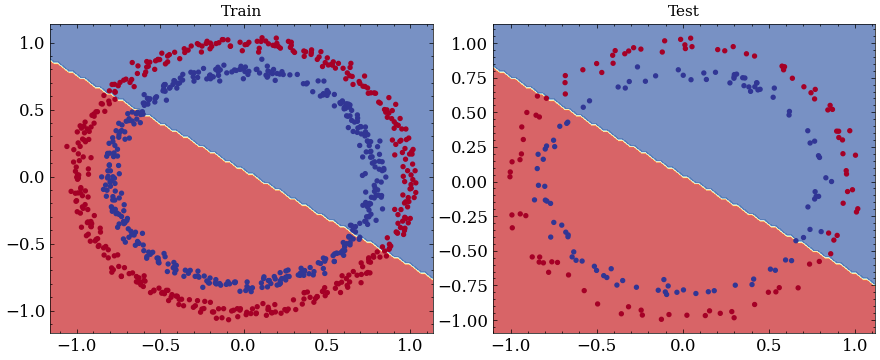

In [25]:
def plot_decision_boundary(model, X, y):
    # colours the plane by the model's prediction; works for binary (sigmoid) and multiclass (softmax) models
    dev = next(model.parameters()).device
    X, y = X.cpu(), y.cpu()
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 101), np.linspace(y_min, y_max, 101))
    X_to_pred_on = torch.from_numpy(np.column_stack((xx.ravel(), yy.ravel()))).float().to(dev)
    model.eval()
    with torch.inference_mode():
        y_logits = model(X_to_pred_on)
    if y_logits.ndim > 1 and y_logits.shape[1] > 1:      # one logit per class: softmax, then the largest
        y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)
    else:
        y_pred = torch.round(torch.sigmoid(y_logits))
    plt.contourf(xx, yy, y_pred.reshape(xx.shape).cpu().numpy(), cmap=plt.cm.RdYlBu, alpha=0.7)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=8, cmap=plt.cm.RdYlBu)
    plt.xlim(xx.min(), xx.max()); plt.ylim(yy.min(), yy.max())

def show_boundary(model):
    plt.figure(figsize=(9, 3.8))
    plt.subplot(1, 2, 1); plt.title("Train"); plot_decision_boundary(model, X_train, y_train)
    plt.subplot(1, 2, 2); plt.title("Test"); plot_decision_boundary(model, X_test, y_test)
    plt.tight_layout(); plt.show()
show_boundary(model_0)

The boundary is a straight line, so it can never separate an inner circle from an outer one.

![TensorFlow Playground with linear activations on the circles](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-tensorflow-playground-linear-activation.png)

*The same circles in the online TensorFlow Playground (playground.tensorflow.org): with linear activations, the network draws a straight boundary. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-tensorflow-playground-linear-activation.png) (Daniel Bourke).*

### 3.8 Improving a model

Ways to improve a model, all of them **hyperparameters** in the sense of Week 9:

| change | what it does |
|---|---|
| add layers | more chances to learn patterns |
| add hidden units | more parameters in each layer |
| train longer (more epochs) | more chances to adjust |
| change the activation functions | allows bends, section 3.10 |
| change the learning rate | smaller or larger steps |
| change the loss function | a loss suited to the problem |

A first try: three layers (2 → 10 → 10 → 1) and 1,000 epochs.

Epoch: 0 | Loss: 0.69396, Accuracy: 50.88% | Test loss: 0.69261, Test acc: 51.00%
Epoch: 100 | Loss: 0.69305, Accuracy: 50.38% | Test loss: 0.69379, Test acc: 48.00%
Epoch: 200 | Loss: 0.69299, Accuracy: 51.12% | Test loss: 0.69437, Test acc: 46.00%
Epoch: 300 | Loss: 0.69298, Accuracy: 51.62% | Test loss: 0.69458, Test acc: 45.00%
Epoch: 400 | Loss: 0.69298, Accuracy: 51.12% | Test loss: 0.69465, Test acc: 46.00%


Epoch: 500 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69467, Test acc: 46.00%
Epoch: 600 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%
Epoch: 700 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%
Epoch: 800 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


Epoch: 900 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%
Epoch: 999 | Loss: 0.69298, Accuracy: 51.00% | Test loss: 0.69468, Test acc: 46.00%


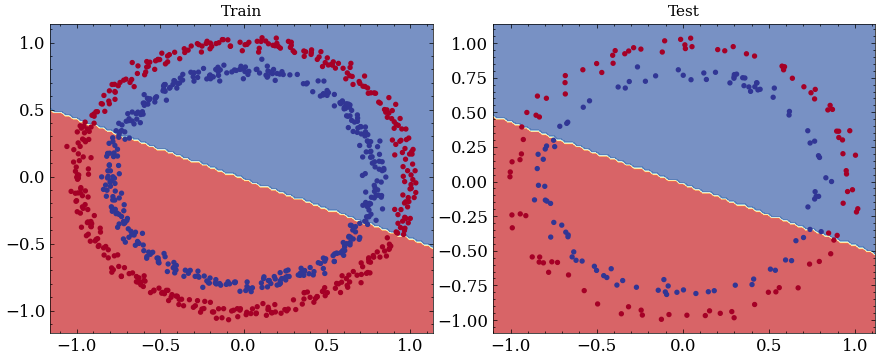

In [26]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
    def forward(self, x):
        return self.layer_3(self.layer_2(self.layer_1(x)))
torch.manual_seed(42)
model_1 = CircleModelV1().to(device)
train_binary(model_1, epochs=1000, every=100)
show_boundary(model_1)

### 3.9 Can the model learn anything? A check on a straight line

Still near 50%. A useful check is to train a similar network on a problem that a straight line solves: data on the line $y = 0.7x + 0.3$ (now 100 points), regression with the L1 loss. If this works, the code is fine and the model is the problem.

Epoch: 0 | Train loss: 0.75986, Test loss: 0.54143
Epoch: 100 | Train loss: 0.09309, Test loss: 0.02901
Epoch: 200 | Train loss: 0.07376, Test loss: 0.02850
Epoch: 300 | Train loss: 0.06745, Test loss: 0.00615
Epoch: 400 | Train loss: 0.06107, Test loss: 0.02004
Epoch: 500 | Train loss: 0.05698, Test loss: 0.01061


Epoch: 600 | Train loss: 0.04857, Test loss: 0.01326
Epoch: 700 | Train loss: 0.06109, Test loss: 0.02127
Epoch: 800 | Train loss: 0.05600, Test loss: 0.01425
Epoch: 900 | Train loss: 0.05571, Test loss: 0.00603
test loss over the last six epochs: [0.0045 0.1262 0.014  0.123  0.0104 0.1357]


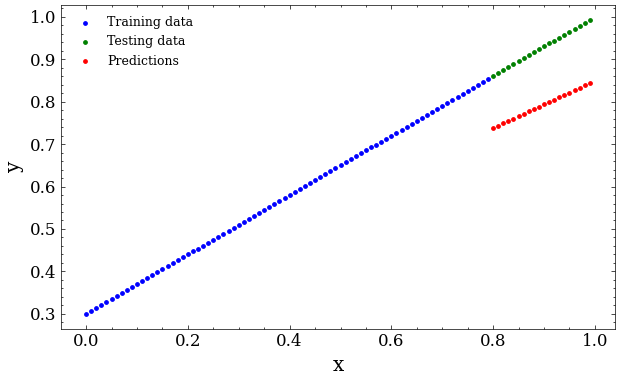

In [27]:
X_regression = torch.arange(0, 1, 0.01).unsqueeze(dim=1)
y_regression = weight * X_regression + bias
train_split = int(0.8 * len(X_regression))
X_train_regression, y_train_regression = X_regression[:train_split].to(device), y_regression[:train_split].to(device)
X_test_regression, y_test_regression = X_regression[train_split:].to(device), y_regression[train_split:].to(device)

def fit_line_net(loss_fn, lr=0.1, epochs=1000, every=100):
    torch.manual_seed(42)
    model = nn.Sequential(nn.Linear(1, 10), nn.Linear(10, 10), nn.Linear(10, 1)).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    test_losses = []
    for epoch in range(epochs):
        model.train()
        loss = loss_fn(model(X_train_regression), y_train_regression)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        model.eval()
        with torch.inference_mode():
            test_loss = loss_fn(model(X_test_regression), y_test_regression)
        test_losses.append(test_loss.item())
        if every and epoch % every == 0:
            print(f"Epoch: {epoch} | Train loss: {loss:.5f}, Test loss: {test_loss:.5f}")
    return model, test_losses

model_2, test_losses = fit_line_net(nn.L1Loss())
print("test loss over the last six epochs:", np.round(test_losses[-6:], 4))
with torch.inference_mode():
    y_preds = model_2(X_test_regression)
plot_predictions(X_train_regression.cpu(), y_train_regression.cpu(), X_test_regression.cpu(), y_test_regression.cpu(), predictions=y_preds.cpu())

The network does learn the line, but its test loss jumps between about 0.005 and 0.13 from one epoch to the next, so the plot depends on where training happens to stop. The reason is the L1 loss: the slope of $|\hat y - y|$ is $\pm 1$ however close the prediction is, so near the bottom the steps do not shrink and the line keeps overshooting. The squared error has slopes that shrink near the bottom; with it, the same network and learning rate settle down.

squared error, test loss over the last six epochs: ['5.5e-14', '5.5e-14', '5.5e-14', '5.5e-14', '5.5e-14', '5.5e-14']


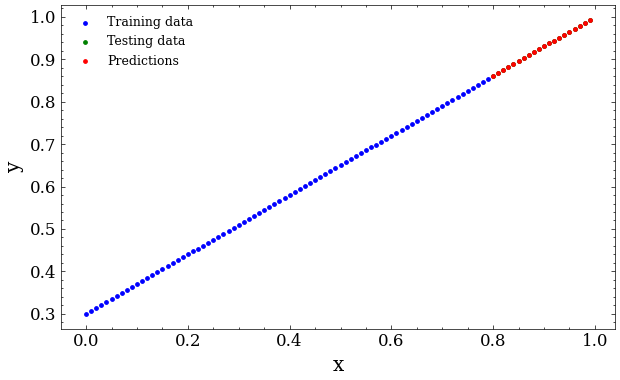

In [28]:
model_2, test_losses = fit_line_net(nn.MSELoss(), every=0)
print("squared error, test loss over the last six epochs:", [f"{v:.1e}" for v in test_losses[-6:]])
with torch.inference_mode():
    y_preds = model_2(X_test_regression)
plot_predictions(X_train_regression.cpu(), y_train_regression.cpu(), X_test_regression.cpu(), y_test_regression.cpu(), predictions=y_preds.cpu())

So the code and the training loop work; the circles fail because of the model itself.

### 3.10 The missing piece: non-linearity

Linear layers without an activation can only draw straight lines, however many are stacked. Two linear layers equal one: $W_2(W_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = (W_2W_1)\mathbf{x} + (W_2\mathbf{b}_1 + \mathbf{b}_2)$. ReLU between the layers adds the bends: each ReLU unit adds one corner, as the lecture showed on one input.

![TensorFlow Playground with ReLU activations on the circles](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-tensorflow-playground-relu-activation.png)

*With ReLU activations, the TensorFlow Playground network separates the circles. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-tensorflow-playground-relu-activation.png) (Daniel Bourke).*

two linear layers equal one linear layer: True
x: [-3. -2. -1.  0.  1.  2.  3.] 
1.0 ReLU(x+1) - 2.0 ReLU(x) + 1.5 ReLU(x-1): [0.  0.  0.  1.  0.  0.5 1. ]  (corners at x = -1, 0, 1)
Epoch: 0 | Loss: 0.69295, Accuracy: 50.00% | Test loss: 0.69319, Test acc: 50.00%


Epoch: 100 | Loss: 0.69115, Accuracy: 52.88% | Test loss: 0.69102, Test acc: 52.50%
Epoch: 200 | Loss: 0.68977, Accuracy: 53.37% | Test loss: 0.68940, Test acc: 55.00%
Epoch: 300 | Loss: 0.68795, Accuracy: 53.00% | Test loss: 0.68723, Test acc: 56.00%


Epoch: 400 | Loss: 0.68517, Accuracy: 52.75% | Test loss: 0.68411, Test acc: 56.50%


Epoch: 500 | Loss: 0.68102, Accuracy: 52.75% | Test loss: 0.67941, Test acc: 56.50%
Epoch: 600 | Loss: 0.67515, Accuracy: 54.50% | Test loss: 0.67285, Test acc: 56.00%
Epoch: 700 | Loss: 0.66659, Accuracy: 58.38% | Test loss: 0.66322, Test acc: 59.00%


Epoch: 800 | Loss: 0.65160, Accuracy: 64.00% | Test loss: 0.64757, Test acc: 67.50%


Epoch: 900 | Loss: 0.62362, Accuracy: 74.00% | Test loss: 0.62145, Test acc: 79.00%
Epoch: 999 | Loss: 0.56890, Accuracy: 87.62% | Test loss: 0.57440, Test acc: 86.50%


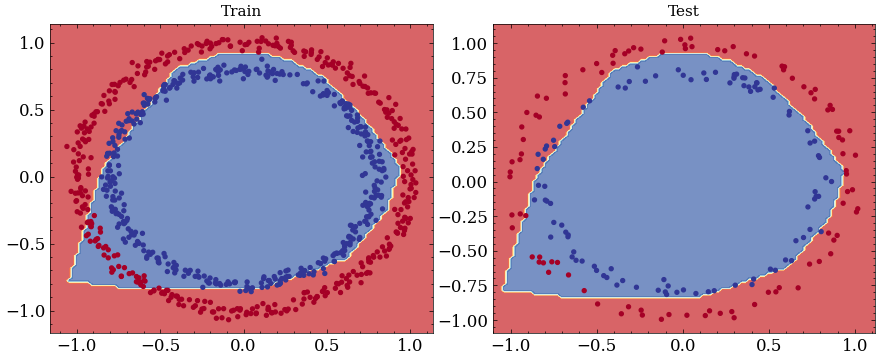

In [29]:
torch.manual_seed(1)
lin2 = nn.Sequential(nn.Linear(3, 5), nn.Linear(5, 2))
W1, b1, W2, b2 = lin2[0].weight, lin2[0].bias, lin2[1].weight, lin2[1].bias
xx_ = torch.randn(4, 3)
print("two linear layers equal one linear layer:", torch.allclose(lin2(xx_), xx_ @ (W2 @ W1).T + (W2 @ b1 + b2), atol=1e-6))
xs = np.linspace(-3, 3, 7); relu_np = lambda z: np.maximum(z, 0)
print("x:", xs, "\n1.0 ReLU(x+1) - 2.0 ReLU(x) + 1.5 ReLU(x-1):", 1.0 * relu_np(xs + 1) - 2.0 * relu_np(xs) + 1.5 * relu_np(xs - 1), " (corners at x = -1, 0, 1)")

class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()
    def forward(self, x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))
torch.manual_seed(42)
model_3 = CircleModelV2().to(device)
acc_1000 = train_binary(model_3, epochs=1000, every=100)
show_boundary(model_3)

After 1,000 epochs the loss is still falling, so the model has not finished learning. Training the same network longer (or with a larger learning rate) shows how far it can go.

Epoch: 0 | Loss: 0.69295, Accuracy: 50.00% | Test loss: 0.69319, Test acc: 50.00%


Epoch: 500 | Loss: 0.68102, Accuracy: 52.75% | Test loss: 0.67941, Test acc: 56.50%


Epoch: 1000 | Loss: 0.56818, Accuracy: 87.75% | Test loss: 0.57378, Test acc: 86.50%


Epoch: 1500 | Loss: 0.12188, Accuracy: 99.62% | Test loss: 0.16512, Test acc: 99.00%


Epoch: 2000 | Loss: 0.04176, Accuracy: 99.88% | Test loss: 0.06583, Test acc: 100.00%


Epoch: 2500 | Loss: 0.02383, Accuracy: 99.88% | Test loss: 0.04363, Test acc: 100.00%


Epoch: 3000 | Loss: 0.01672, Accuracy: 99.88% | Test loss: 0.03363, Test acc: 100.00%


Epoch: 3500 | Loss: 0.01288, Accuracy: 100.00% | Test loss: 0.02841, Test acc: 99.50%


Epoch: 3999 | Loss: 0.01049, Accuracy: 100.00% | Test loss: 0.02451, Test acc: 99.50%
test accuracy after 1,000 epochs 86.5%, after 4,000 epochs 99.5%


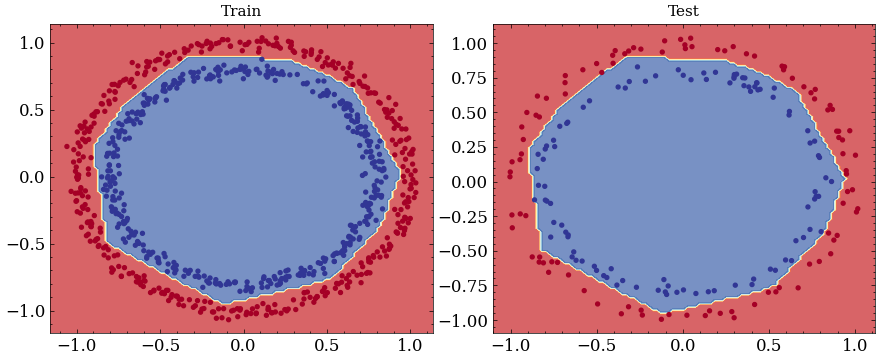

In [30]:
torch.manual_seed(42)
model_3 = CircleModelV2().to(device)
acc_long = train_binary(model_3, epochs=4000, every=500)
print(f"test accuracy after 1,000 epochs {acc_1000:.1f}%, after 4,000 epochs {acc_long:.1f}%")
show_boundary(model_3)

### 3.11 Activation functions by hand

ReLU and the sigmoid are short formulas; writing them out shows there is no magic in `nn.ReLU()` and `torch.sigmoid`.

same as PyTorch: True True


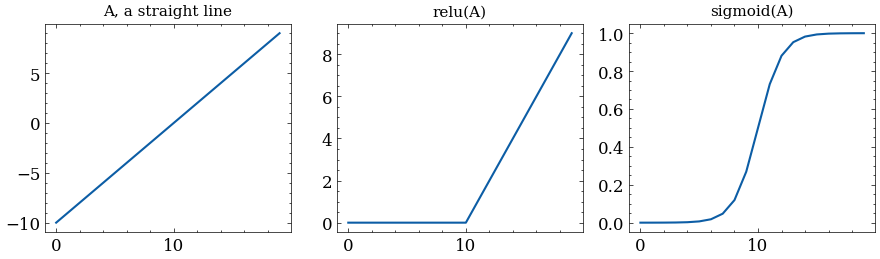

In [31]:
A = torch.arange(-10, 10, 1, dtype=torch.float32)
def relu(x):
    return torch.maximum(torch.tensor(0), x)
def sigmoid(x):
    return 1 / (1 + torch.exp(-x))
print("same as PyTorch:", torch.equal(relu(A), torch.relu(A)), torch.allclose(sigmoid(A), torch.sigmoid(A)))
fig, ax = plt.subplots(1, 3, figsize=(9, 2.8))
ax[0].plot(A); ax[0].set_title("A, a straight line")
ax[1].plot(relu(A)); ax[1].set_title("relu(A)")
ax[2].plot(sigmoid(A)); ax[2].set_title("sigmoid(A)")
plt.tight_layout(); plt.show()

### 3.12 Multiclass classification

Four clusters of points ("blobs"), one class each.

![binary versus multiclass classification](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-binary-vs-multi-class-classification.png)

*Binary versus multiclass classification. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-binary-vs-multi-class-classification.png) (Daniel Bourke).*

 The network ends in **one logit per class**. **Softmax** turns the logits into probabilities that add up to 1, $p_k = e^{s_k}/\sum_j e^{s_j}$, and `argmax` picks the class. The loss `nn.CrossEntropyLoss` takes the raw logits and charges $-\ln p_y$ for the true class $y$. First the lecture's numbers: scores 2.0, 1.0, 0.1.

In [32]:
s_ = torch.tensor([2.0, 1.0, 0.1])
p = torch.softmax(s_, dim=0)
print("scores", s_.tolist(), "-> probabilities", p.numpy().round(3))
for k in range(3):
    print(f"true class {k}: cross-entropy -ln p = {-torch.log(p[k]).item():.3f}",
          f"(nn.functional.cross_entropy: {nn.functional.cross_entropy(s_[None], torch.tensor([k])).item():.3f})")
print("a confident correct answer, p = 0.99:", round(-np.log(0.99), 3), "; a confident wrong one, p = 0.01:", round(-np.log(0.01), 3))

scores [2.0, 1.0, 0.10000000149011612] -> probabilities [0.659 0.242 0.099]
true class 0: cross-entropy -ln p = 0.417 (nn.functional.cross_entropy: 0.417)
true class 1: cross-entropy -ln p = 1.417 (nn.functional.cross_entropy: 1.417)
true class 2: cross-entropy -ln p = 2.317 (nn.functional.cross_entropy: 2.317)
a confident correct answer, p = 0.99: 0.01 ; a confident wrong one, p = 0.01: 4.605


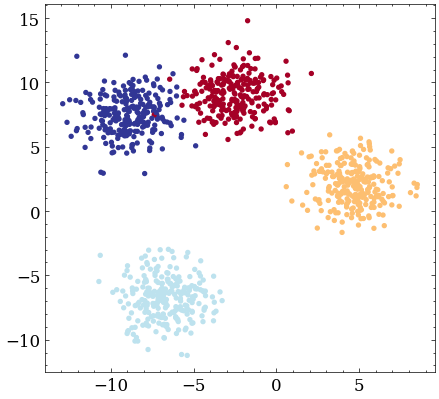

logits of 3 test points:
 tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
        [-0.0973, -0.9431, -0.5963, -0.1371],
        [ 0.2528, -0.2379,  0.1882, -0.0066]]) 
softmax:
 tensor([[0.3169, 0.3244, 0.1405, 0.2182],
        [0.3336, 0.1432, 0.2026, 0.3206],
        [0.3011, 0.1843, 0.2823, 0.2323]]) 
rows add up to tensor([1.0000, 1.0000, 1.0000])


In [33]:
from sklearn.datasets import make_blobs
NUM_CLASSES, NUM_FEATURES, RANDOM_SEED = 4, 2, 42
X_blob, y_blob = make_blobs(n_samples=1000, n_features=NUM_FEATURES, centers=NUM_CLASSES, cluster_std=1.5, random_state=RANDOM_SEED)
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)          # class labels are integers
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob, y_blob, test_size=0.2, random_state=RANDOM_SEED)
plt.figure(figsize=(4.6, 4.2)); plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu, s=8); plt.tight_layout(); plt.show()

class BlobModel(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8):
        super().__init__()
        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features))
    def forward(self, x):
        return self.linear_layer_stack(x)
torch.manual_seed(42)
model_4 = BlobModel(input_features=NUM_FEATURES, output_features=NUM_CLASSES, hidden_units=8).to(device)
X_blob_train, y_blob_train, X_blob_test, y_blob_test = X_blob_train.to(device), y_blob_train.to(device), X_blob_test.to(device), y_blob_test.to(device)
with torch.inference_mode():
    y_logits = model_4(X_blob_test)
print("logits of 3 test points:\n", y_logits[:3], "\nsoftmax:\n", torch.softmax(y_logits, dim=1)[:3], "\nrows add up to", torch.softmax(y_logits, dim=1)[:3].sum(dim=1))

Epoch: 0 | Loss: 1.15883, Acc: 40.38% | Test Loss: 1.07554, Test Acc: 48.00%
Epoch: 10 | Loss: 0.64476, Acc: 96.75% | Test Loss: 0.66069, Test Acc: 97.50%
Epoch: 20 | Loss: 0.42535, Acc: 98.50% | Test Loss: 0.43074, Test Acc: 100.00%
Epoch: 30 | Loss: 0.25294, Acc: 99.12% | Test Loss: 0.24508, Test Acc: 99.50%
Epoch: 40 | Loss: 0.11232, Acc: 99.25% | Test Loss: 0.10229, Test Acc: 99.50%
Epoch: 50 | Loss: 0.06627, Acc: 99.25% | Test Loss: 0.05848, Test Acc: 99.50%
Epoch: 60 | Loss: 0.05068, Acc: 99.25% | Test Loss: 0.04293, Test Acc: 99.50%
Epoch: 70 | Loss: 0.04300, Acc: 99.25% | Test Loss: 0.03491, Test Acc: 99.50%
Epoch: 80 | Loss: 0.03836, Acc: 99.25% | Test Loss: 0.02988, Test Acc: 99.50%


Epoch: 90 | Loss: 0.03525, Acc: 99.25% | Test Loss: 0.02663, Test Acc: 99.50%
Epoch: 99 | Loss: 0.03331, Acc: 99.25% | Test Loss: 0.02453, Test Acc: 99.50%


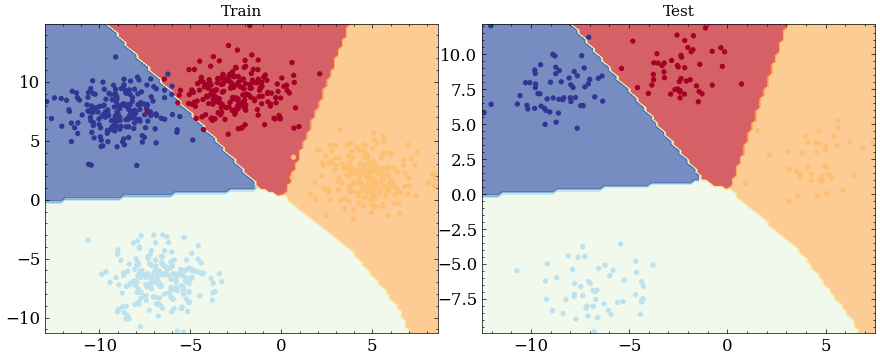

In [34]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_4.parameters(), lr=0.1)
torch.manual_seed(42)
for epoch in range(100):
    model_4.train()
    y_logits = model_4(X_blob_train)
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)
    loss = loss_fn(y_logits, y_blob_train)
    acc = accuracy_fn(y_true=y_blob_train, y_pred=y_pred)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    model_4.eval()
    with torch.inference_mode():
        test_logits = model_4(X_blob_test)
        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
        test_loss = loss_fn(test_logits, y_blob_test)
        test_acc = accuracy_fn(y_true=y_blob_test, y_pred=test_pred)
    if epoch % 10 == 0 or epoch == 99:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")
plt.figure(figsize=(9, 3.8))
plt.subplot(1, 2, 1); plt.title("Train"); plot_decision_boundary(model_4, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2); plt.title("Test"); plot_decision_boundary(model_4, X_blob_test, y_blob_test)
plt.tight_layout(); plt.show()

### 3.13 More evaluation metrics

Week 9's tools judge any classifier: the confusion matrix, precision and recall per class. (The library `torchmetrics` offers the same functions for PyTorch tensors.)

In [35]:
from sklearn.metrics import confusion_matrix, classification_report
y_true_np, y_pred_np = y_blob_test.cpu().numpy(), test_pred.cpu().numpy()
print(confusion_matrix(y_true_np, y_pred_np))
print(classification_report(y_true_np, y_pred_np, digits=3))

[[49  0  0  0]
 [ 0 41  0  0]
 [ 0  0 53  0]
 [ 1  0  0 56]]
              precision    recall  f1-score   support

           0      0.980     1.000     0.990        49
           1      1.000     1.000     1.000        41
           2      1.000     1.000     1.000        53
           3      1.000     0.982     0.991        57

    accuracy                          0.995       200
   macro avg      0.995     0.996     0.995       200
weighted avg      0.995     0.995     0.995       200



## 4. Mini-batches, validation, and early stopping: diamond prices

The networks so far saw the whole training set at every step. Larger data sets are trained in **mini-batches**: shuffle the training set, cut it into batches of, say, 256 examples, and take one gradient step per batch; one pass through all batches is an epoch. Three more habits make training reliable:

- **Prepare the inputs.** Standardize every numerical feature with the training set's mean and standard deviation, and apply the same numbers to validation and test data. Code ordered categories as integers and unordered ones as one-hot columns (Week 9). Scale the label to moderate numbers, here the price in thousands of dollars.
- **Hold out a validation set** from the training data, used only to watch the loss and to choose when to stop. The test set stays untouched until the end.
- **Early stopping.** Keep the weights of the epoch with the lowest validation loss, and stop once it has not improved for a number of epochs, the *patience*.

The optimizer is **Adam** with learning rate 0.001, a good default; it adapts the step length of every weight separately. Week 9's split is reused (80/20, `random_state=0`), so the test RMSE compares directly with the trees and forests of Week 9.

In [36]:
order = {"cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"], "color": list("JIHGFED"),
         "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]}
Xd = d[["carat", "cut", "color", "clarity", "depth", "table", "x", "y", "z"]].copy()
for col, levels in order.items():
    Xd[col] = Xd[col].map({v: i for i, v in enumerate(levels)})
yd = d["price"]
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=0)            # Week 9's split
Xfit, Xval, yfit, yval = train_test_split(Xtr, ytr, test_size=0.1, random_state=0)    # validation for early stopping
mu, sd = Xfit.mean(), Xfit.std()
T = lambda A: torch.tensor(((A - mu) / sd).values, dtype=torch.float32)
Yt = lambda v: torch.tensor(v.values / 1000, dtype=torch.float32)[:, None]             # price in thousand $
Xf, Yf, Xv, Yv, Xt, Yte = T(Xfit), Yt(yfit), T(Xval), Yt(yval), T(Xte), Yt(yte)
print("fit", len(Xf), " validation", len(Xv), " test", len(Xt), " mini-batches per epoch", int(np.ceil(len(Xf) / 256)))

def train(model, Xf, Yf, Xv, Yv, lossf, lr=1e-3, batch=256, max_epochs=200, patience=10, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist, best, best_state, wait = [], np.inf, None, 0
    for ep in range(max_epochs):
        model.train(); perm = torch.randperm(len(Xf)); tot = 0.0
        for i in range(0, len(Xf), batch):
            idx = perm[i:i + batch]
            loss = lossf(model(Xf[idx]), Yf[idx])   # forward pass and loss on one mini-batch
            opt.zero_grad()                          # zero the gradients
            loss.backward()                          # backward pass
            opt.step()                               # step
            tot += loss.item() * len(idx)
        model.eval()
        with torch.inference_mode():
            v = lossf(model(Xv), Yv).item()
        hist.append((tot / len(Xf), v))
        if v < best - 1e-6:
            best, best_state, wait = v, {k: t.clone() for k, t in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)                # keep the weights of the best validation epoch
    return np.array(hist)

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(9, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
print("parameters:", sum(p.numel() for p in net.parameters()))
hist = train(net, Xf, Yf, Xv, Yv, nn.MSELoss())
best_ep = int(hist[:, 1].argmin()) + 1
with torch.inference_mode():
    rmse_te = 1000 * ((net(Xt) - Yte) ** 2).mean().sqrt().item()
print(f"stopped after {len(hist)} epochs; best validation epoch {best_ep}")
print(f"network test RMSE: {rmse_te:.0f} $   (Week 9 on the same test set: line 1,198 $, tree 636 $, forest 536 $)")

fit 38836  validation 4316  test 10788  mini-batches per epoch 152
parameters: 4865


stopped after 82 epochs; best validation epoch 72
network test RMSE: 552 $   (Week 9 on the same test set: line 1,198 $, tree 636 $, forest 536 $)


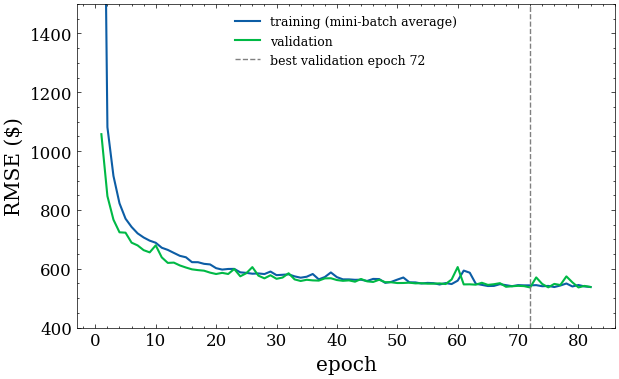

In [37]:
ep = np.arange(1, len(hist) + 1)
plt.plot(ep, 1000 * np.sqrt(hist[:, 0]), label="training (mini-batch average)")
plt.plot(ep, 1000 * np.sqrt(hist[:, 1]), label="validation")
plt.axvline(best_ep, color="gray", ls="--", lw=1, label=f"best validation epoch {best_ep}")
plt.ylim(400, 1500); plt.xlabel("epoch"); plt.ylabel("RMSE ($)"); plt.legend(); plt.tight_layout(); plt.show()

The hyperparameters of a network, all chosen with the validation set and never with the test set:

| choice | typical values | what it controls |
|---|---|---|
| hidden layers and units | 1–3 layers of 16–256 units | flexibility, risk of overfitting |
| activation | ReLU (hidden), none or softmax (output) | shape of the pieces |
| loss | MSE or cross-entropy | what counts as wrong |
| optimizer and learning rate | Adam 0.001, or SGD 0.01–0.1 | speed and stability of training |
| batch size | 32–512 | noise and cost of each step |
| epochs, patience | until early stopping, patience 10 | how long to train |

## 5. Handwritten digits

1,797 images of 8×8 pixels (grey levels 0–16), each a handwritten digit 0–9. Each image becomes a vector of 64 features, divided by 16 to lie between 0 and 1; the network ends in 10 logits, one per digit, and is trained with the cross-entropy, in mini-batches of 32 with early stopping.

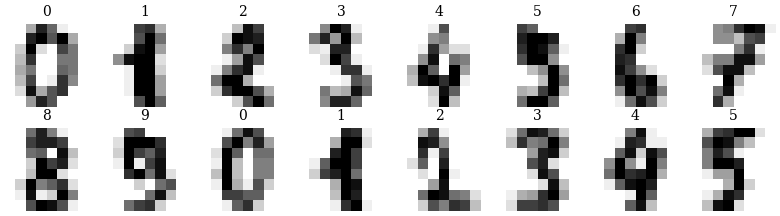

fit 1144  validation 203  test 450
parameters: 4810


network test accuracy 0.976 after 146 epochs;  random forest test accuracy 0.987
[[45  0  0  0  0  0  0  0  0  0]
 [ 0 45  0  0  0  0  0  0  1  0]
 [ 0  1 43  0  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  1  0  0 43  0  0  0  1  0]
 [ 0  0  0  0  0 46  0  0  0  0]
 [ 0  1  0  0  0  0 44  0  0  0]
 [ 0  0  0  0  0  0  0 45  0  0]
 [ 0  3  0  0  0  0  0  0 39  1]
 [ 0  0  0  1  0  1  0  0  0 43]]
largest confusions (count, true, predicted): [(3, 8, 1), (1, 9, 5), (1, 9, 3), (1, 8, 9)]


In [38]:
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
dg = load_digits()
fig, ax = plt.subplots(2, 8, figsize=(8, 2.3))
for a, im, lab in zip(ax.flat, dg.images, dg.target):
    a.imshow(im, cmap="gray_r"); a.set_title(str(lab), fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()

Dtr, Dte, ltr, lte = train_test_split(dg.data / 16, dg.target, test_size=0.25, random_state=0, stratify=dg.target)
Dfit, Dval, lfit, lval = train_test_split(Dtr, ltr, test_size=0.15, random_state=0, stratify=ltr)
F_ = lambda A: torch.tensor(A, dtype=torch.float32); L_ = lambda v: torch.tensor(v)
print("fit", len(Dfit), " validation", len(Dval), " test", len(Dte))
torch.manual_seed(0)
dnet = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
print("parameters:", sum(p.numel() for p in dnet.parameters()))
dh = train(dnet, F_(Dfit), L_(lfit), F_(Dval), L_(lval), nn.CrossEntropyLoss(), batch=32, patience=15)
with torch.inference_mode():
    pred = dnet(F_(Dte)).argmax(1).numpy()
acc_net = (pred == lte).mean()
rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(Dtr, ltr)
print(f"network test accuracy {acc_net:.3f} after {len(dh)} epochs;  random forest test accuracy {rf.score(Dte, lte):.3f}")
cm = confusion_matrix(lte, pred); print(cm)
off = [(int(cm[i, j]), i, j) for i in range(10) for j in range(10) if i != j and cm[i, j] > 0]
print("largest confusions (count, true, predicted):", sorted(off, reverse=True)[:4])

## 6. Overfitting a small data set, and early stopping

Twenty noisy points of $y = \sin(3x)$, a network with two hidden layers of 100 units, and full-batch training for 3,000 steps. The validation loss falls, reaches its minimum, and rises again while the training loss keeps falling: the moment to stop is the minimum of the validation curve.

lowest validation MSE 0.096 at step 38 (training MSE 0.069); at step 3000: training 0.0058, validation 0.129


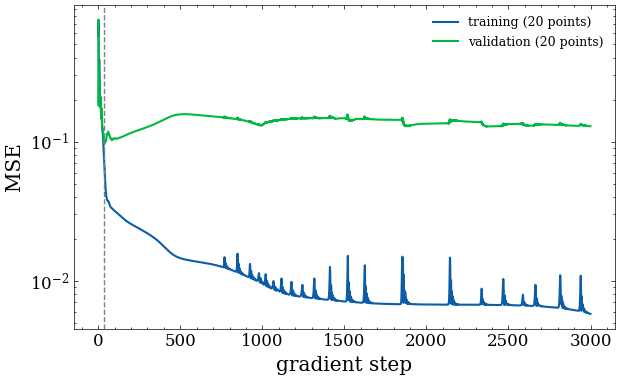

In [39]:
rng = np.random.default_rng(3)
xs_ = np.sort(rng.uniform(-1, 1, 40)); ys_ = np.sin(3 * xs_) + rng.normal(0, 0.25, 40)
tr_i = np.arange(40) % 2 == 0
Xa, Ya = torch.tensor(xs_[tr_i, None], dtype=torch.float32), torch.tensor(ys_[tr_i, None], dtype=torch.float32)
Xb, Yb = torch.tensor(xs_[~tr_i, None], dtype=torch.float32), torch.tensor(ys_[~tr_i, None], dtype=torch.float32)
torch.manual_seed(0)
big = nn.Sequential(nn.Linear(1, 100), nn.Tanh(), nn.Linear(100, 100), nn.Tanh(), nn.Linear(100, 1))
opt = torch.optim.Adam(big.parameters(), lr=0.01); H = []
for step in range(3000):
    opt.zero_grad(); l = ((big(Xa) - Ya) ** 2).mean(); l.backward(); opt.step()
    with torch.no_grad():
        H.append((l.item(), ((big(Xb) - Yb) ** 2).mean().item()))
H = np.array(H); k = H[:, 1].argmin()
print(f"lowest validation MSE {H[k, 1]:.3f} at step {k + 1} (training MSE {H[k, 0]:.3f}); at step 3000: training {H[-1, 0]:.4f}, validation {H[-1, 1]:.3f}")
plt.semilogy(H[:, 0], label="training (20 points)"); plt.semilogy(H[:, 1], label="validation (20 points)")
plt.axvline(k, color="gray", ls="--", lw=1); plt.xlabel("gradient step"); plt.ylabel("MSE"); plt.legend(); plt.tight_layout(); plt.show()

## Practice exercises

**These are practice for yourself, and they are not the graded assignments.** Problem sets are released separately on Blackboard, with due dates.

1. **Tensors.** Create a random tensor of shape (7, 7) and multiply it by a random tensor of shape (1, 7); fix the shape error with a transpose. Repeat after `torch.manual_seed(0)` and check that the result is the same. Find the maximum, the minimum, and their positions.
2. **Counting parameters.** How many weights and biases does a network with layers 64 → 32 → 10 have? Check with `sum(p.numel() for p in model.parameters())`.
3. **The workflow.** Make line data with weight 0.3 and bias 0.9 (at least 100 points), split it 80/20, and train `LinearRegressionModel` with `nn.L1Loss` and SGD (learning rate 0.01) for 300 epochs, testing every 20 epochs. Plot the predictions, save the model, load it into a new instance and check that the predictions match.
4. **Backpropagation by hand.** In the tiny network of section 2.4, change the target to $y = 2$. Redo the forward and backward pass by hand and check with autograd.
5. **Two moons.** Make `make_moons(n_samples=1000, noise=0.03, random_state=42)`, split it 80/20, build a network with ReLU activations, and train it to above 96% test accuracy. Plot its decision boundary.
6. **Tanh by hand.** Write the hyperbolic tangent $\tanh x = (e^x - e^{-x})/(e^x + e^{-x})$ with PyTorch operations and compare it with `torch.tanh`.
7. **Early stopping.** In section 6, rerun the experiment with 8 units per layer instead of 100. Does the validation loss still turn up?
